# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 01 - Comprensión dataset

## Objetivo

En este notebook se realiza una primera exploración del dataset C-MAPSS, comenzando por el subconjunto FD001, con el objetivo de comprender su estructura, las variables disponibles y el comportamiento temporal de los motores.

En concreto, se pretende:

- Cargar y estructurar correctamente los datos de `train_FD001.txt`.
- Analizar las dimensiones, tipos de variables y posibles valores ausentes.
- Estudiar la estructura temporal de los motores y la duración de sus trayectorias.
- Analizar las condiciones operativas y las mediciones de los sensores.
- Identificar variables constantes o con baja variabilidad.
- Estudiar la evolución de los sensores a lo largo de la vida de los motores.
- Calcular la vida útil restante (RUL) para los datos de entrenamiento.
- Analizar la relación entre las mediciones de los sensores y la RUL.

Este análisis servirá como base para comprender el comportamiento del dataset antes de abordar las etapas posteriores de preprocesamiento y modelado.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para la manipulación, análisis y visualización de los datos:

- **Pandas:** carga, estructuración y análisis de los datos.
- **Matplotlib:** representación gráfica y análisis visual de las series temporales.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Comprensión del dataset C-MAPSS

En este notebook se realiza una primera exploración práctica del conjunto de datos C-MAPSS (*Turbofan Engine Degradation Simulation*), desarrollado por NASA (https://data.phmsociety.org/nasa/).

Este dataset contiene series temporales simuladas de motores turbofán que experimentan procesos de degradación progresiva hasta alcanzar una condición de fallo. Está organizado en cuatro subconjuntos (FD001, FD002, FD003 y FD004), que presentan diferentes condiciones operativas y modos de degradación.

El objetivo de esta fase es comprender la estructura y el contenido del dataset antes de realizar el análisis exploratorio, preprocesamiento y modelado.

Inicialmente se trabajará con el **subconjunto FD001**, caracterizado por una única condición operativa y un modo de degradación asociado al compresor de alta presión (HPC).

### 1.1 Carga de datos

In [ ]:
# Conexión con Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Definimos unas variables globales que serán las rutas de los archivos y directorios que iremos necesitando a lo largo del notebook.

In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"

En el README hemos visto que el archivo tiene 26 columnas:
* 1 identificador del motor.
* 1 ciclo temporal.
* 3 configuraciones operacionales.
* 21 sensores.

Por tanto, creamos las cabeceras de la tabla.

In [ ]:
column_names = (
    ["unit", "cycle"] +
    [f"op_setting_{i}" for i in range(1, 4)] +
    [f"sensor_{i}" for i in range(1, 22)]
)

print(column_names)
print("Número de columnas:", len(column_names))

['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
Número de columnas: 26


Por último, cargamos el archivo que vamos a analizar.

In [ ]:
df = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=column_names    # names=column_names asigna los nombres que acabamos de definir
)

### 1.2 Primera visualización de los datos

Una vez cargado el archivo `train_FD001.txt` en un DataFrame, se realiza una primera visualización de los datos para comprobar su estructura y verificar que las variables se han cargado con las cabeceras definidas anteriormente.

Para ello, se muestran las primeras cinco observaciones del conjunto de datos.

In [ ]:
df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Las primeras filas permiten comprobar que los datos se han cargado como esperábamos y observar la estructura del conjunto de datos.

Cada fila representa el estado de un motor en un ciclo de funcionamiento determinado. Las variables se organizan de la siguiente forma:

- **`unit`**: identificador del motor.
- **`cycle`**: ciclo de funcionamiento en el que se realiza la observación.
- **`op_setting_1` - `op_setting_3`**: tres variables que representan las condiciones operativas del motor.
- **`sensor_1` - `sensor_21`**: mediciones obtenidas de los 21 sensores del motor.

Por tanto, cada motor está representado por múltiples filas ordenadas temporalmente según el número de ciclo, formando una serie temporal multivariante.

En las primeras cinco observaciones se muestran los ciclos 1 a 5 del motor 1. Se puede observar que algunas variables permanecen prácticamente constantes, mientras que otras presentan pequeñas variaciones entre ciclos. Su comportamiento se analizará posteriormente durante el análisis exploratorio de datos.

### 1.3 Dimensiones del conjunto de datos

Vamos a comprobar qué tamaño tiene realmente el dataset y cuántos motores contiene.

In [ ]:
print("Tamaño del dataset:", df.shape)
print("Número de motores: ", df["unit"].nunique())

Tamaño del dataset: (20631, 26)
Número de motores:  100


El conjunto de entrenamiento FD001 contiene **20.631 observaciones** y **26 variables**, correspondientes a **100 motores diferentes**.

Cada observación representa un ciclo de funcionamiento de un motor. Por tanto, las 20.631 filas corresponden al conjunto de ciclos registrados para los 100 motores, formando **100 series temporales independientes**, una por cada motor.

El número de motores coincide con la información proporcionada en la documentación oficial del dataset para el **subconjunto FD001**.

### 1.4 Número de ciclos por motor

Ahora ya sabemos que hay 100 motores, pero una pregunta que tenemos que responder es: **¿Todos los motores funcionan durante el mismo número de ciclos antes de fallar?**

In [ ]:
cycles_per_engine = df.groupby("unit")["cycle"].max()
print(cycles_per_engine)

unit
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64


Se ha calculado el último ciclo registrado para cada uno de los 100 motores del conjunto de entrenamiento.

Se observa que las series temporales presentan diferentes longitudes, es decir, los motores no alcanzan el final de su vida útil tras el mismo número de ciclos. Por ejemplo, el motor 1 dispone de 192 ciclos registrados, mientras que el motor 2 alcanza los 287 ciclos.

Dado que en el conjunto de entrenamiento cada motor se observa hasta el fallo, el ciclo máximo de cada unidad representa la longitud total de su serie temporal hasta alcanzar dicho estado.

### 1.5 Distribución de la duración de los motores

Una vez calculado el número de ciclos registrado para cada motor, se analizan estadísticamente las longitudes de las 100 series temporales con el objetivo de conocer su distribución y la variabilidad existente entre ellas.

In [ ]:
cycles_per_engine.describe()

,cycle
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


| Estadístico | Resultado | Interpretación |
|---|---:|---|
| **count** | 100 | Hay 100 motores |
| **mean** | 206,31 | De media, las series duran aproximadamente 206 ciclos |
| **std** | 46,34 | Existe variabilidad en la duración de las series entre motores |
| **min** | 128 | La serie temporal más corta tiene 128 ciclos |
| **25%** | 177 | El 25 % de los motores tiene 177 ciclos o menos |
| **50%** | 199 | La mediana es de 199 ciclos |
| **75%** | 229,25 | El 75 % de los motores tiene 229,25 ciclos o menos |
| **max** | 362 | La serie temporal más larga tiene 362 ciclos |

Los 100 motores presentan diferentes longitudes de serie temporal. La duración media es de **206,31 ciclos**, mientras que la mediana se sitúa en **199 ciclos**.

La serie más corta contiene **128 ciclos** y la más larga **362 ciclos**, con una desviación estándar de aproximadamente **46,34 ciclos**. Por tanto, existe una variabilidad considerable en el número de ciclos registrados para cada motor antes de alcanzar el final de su vida útil.

Los cuartiles muestran que el 50 % central de los motores presenta una duración aproximada de entre **177 y 229 ciclos**.

La suma de los ciclos de los 100 motores corresponde a las **20.631 observaciones** que componen el conjunto de entrenamiento FD001.

### 1.6 Análisis de las variables

Una vez conocida la estructura general del conjunto de datos y la longitud de las series temporales, se analiza la información contenida en sus 26 variables.

En primer lugar, se comprueban los tipos de datos y la presencia de valores no nulos mediante `info()`. Posteriormente, se analizarán los valores ausentes y el número de valores únicos de cada variable.

#### 1.6.1 Tipos de datos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit          20631 non-null  int64  
 1   cycle         20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   sensor_1      20631 non-null  float64
 6   sensor_2      20631 non-null  float64
 7   sensor_3      20631 non-null  float64
 8   sensor_4      20631 non-null  float64
 9   sensor_5      20631 non-null  float64
 10  sensor_6      20631 non-null  float64
 11  sensor_7      20631 non-null  float64
 12  sensor_8      20631 non-null  float64
 13  sensor_9      20631 non-null  float64
 14  sensor_10     20631 non-null  float64
 15  sensor_11     20631 non-null  float64
 16  sensor_12     20631 non-null  float64
 17  sensor_13     20631 non-null  float64
 18  sensor_14     20631 non-nu

El conjunto de datos está compuesto exclusivamente por variables numéricas. De las 26 variables, **22 son de tipo `float64` y 4 de tipo `int64`**.
* `unit` y `cycle` son variables enteras que identifican el motor y el ciclo de funcionamiento, respectivamente.
* Las tres condiciones operativas (`op_setting_1` - `op_setting_3`) son variables numéricas continuas.
* Los 21 sensores también contienen información numérica. La mayoría son de tipo `float64`, mientras que `sensor_17` y `sensor_18` son de tipo `int64`.

Además, todas las columnas contienen **20.631 valores no nulos**, coincidiendo con el número total de observaciones. Por tanto, inicialmente no se observan valores ausentes en el conjunto de datos. No obstante, se realizará una comprobación específica de los valores ausentes en el siguiente apartado.

#### 1.6.2 Valores ausentes

In [ ]:
df.isnull().sum()

,0
unit,0
cycle,0
op_setting_1,0
op_setting_2,0
op_setting_3,0
sensor_1,0
sensor_2,0
sensor_3,0
sensor_4,0
sensor_5,0


Se ha comprobado la presencia de valores ausentes en las 26 variables del conjunto de datos. Todas las columnas presentan **0 valores nulos**, por lo que el conjunto de entrenamiento FD001 está completo en este aspecto.

Por tanto, para **FD001** no será necesario aplicar técnicas de eliminación o imputación de valores ausentes durante el preprocesamiento.

#### 1.6.3 Valores únicos de las variables

In [ ]:
df.nunique()

,0
unit,100
cycle,362
op_setting_1,158
op_setting_2,13
op_setting_3,1
sensor_1,1
sensor_2,310
sensor_3,3012
sensor_4,4051
sensor_5,1


El análisis del número de valores únicos permite realizar una primera evaluación de la variabilidad de las variables.

Las variables `unit` y `cycle` presentan 100 y 362 valores únicos, respectivamente. Los 100 valores de `unit` corresponden a los motores del conjunto de entrenamiento, mientras que los 362 valores de `cycle` están relacionados con la longitud máxima observada de las series temporales.

En cuanto a las condiciones operativas, `op_setting_3` presenta un único valor en todo el conjunto de datos, mientras que `op_setting_1` y `op_setting_2` muestran 158 y 13 valores únicos, respectivamente. Posteriormente se analizará con mayor detalle su distribución y variabilidad.

Respecto a las mediciones de los sensores, se identifican seis variables constantes:

* `sensor_1`
* `sensor_5`
* `sensor_10`
* `sensor_16`
* `sensor_18`
* `sensor_19`

Estas variables presentan un único valor durante las 20.631 observaciones, por lo que no aportan variabilidad dentro del subconjunto FD001. Además, `sensor_6` presenta únicamente dos valores diferentes.

Por otro lado, existen sensores con una elevada cantidad de valores distintos. No obstante, el número de valores únicos por sí solo no permite determinar la relevancia de un sensor para representar la degradación del motor. Esta relación deberá estudiarse posteriormente durante el análisis exploratorio.

### 1.7 Estadísticas descriptivas

A continuación, se analizan las principales estadísticas descriptivas de las variables numéricas con el objetivo de conocer su distribución, rango y variabilidad.

Este análisis permite observar las diferentes escalas de las variables y complementar el estudio previo del número de valores únicos, sin realizar todavía ninguna selección o transformación de las características.

In [ ]:
df.describe()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.737553,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


Las estadísticas descriptivas muestran que las variables del conjunto de datos presentan escalas y niveles de variabilidad muy diferentes.

Las condiciones operativas y las mediciones de los sensores se encuentran en rangos muy distintos. Algunas variables presentan valores muy pequeños, mientras que determinados sensores alcanzan valores de cientos o miles de unidades. Esta diferencia de escalas deberá tenerse en cuenta posteriormente durante el preprocesamiento, especialmente para aquellos modelos sensibles a la magnitud de las variables.

También se confirma la existencia de variables constantes. `op_setting_3` y los sensores `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` no presentan variación dentro de FD001, coincidiendo con lo observado previamente mediante el número de valores únicos.

Por otro lado, numerosos sensores sí presentan variabilidad a lo largo de las observaciones. Sin embargo, esta variabilidad no implica necesariamente que sean relevantes para representar la degradación del motor. Para determinarlo será necesario estudiar posteriormente su evolución temporal.

Las estadísticas correspondientes a `unit` deben interpretarse con precaución, ya que esta variable actúa únicamente como identificador del motor y sus estadísticos descriptivos no tienen significado físico. Del mismo modo, las estadísticas de `cycle` corresponden al conjunto de observaciones y no deben confundirse con las estadísticas de duración de las trayectorias calculadas anteriormente para cada motor.

## 2. Exploración de las series temporales

Una vez comprendida la estructura general del conjunto de datos, se comienza a analizar su naturaleza temporal.

Cada motor constituye una serie temporal independiente formada por las mediciones registradas durante sus diferentes ciclos de funcionamiento. En primer lugar, se analizará individualmente el motor 1 para comprender cómo se representa la evolución completa de un motor dentro del conjunto de datos.

### 2.1 Análisis individual del motor 1

In [ ]:
engine_1 = df[df["unit"] == 1]

print("Número de observaciones:", len(engine_1))
print("Primer ciclo:", engine_1["cycle"].min())
print("Último ciclo:", engine_1["cycle"].max())

Número de observaciones: 192
Primer ciclo: 1
Último ciclo: 192


Las 192 filas del motor 1 constituyen una serie temporal completa desde su primer ciclo registrado hasta el final de su vida simulada.

In [ ]:
engine_1.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:
engine_1.tail()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,519.79,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,519.58,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,520.04,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,519.57,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,520.08,2388.32,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649


El motor 1 contiene **192 observaciones consecutivas**, correspondientes a los ciclos 1 a 192. Por tanto, estas observaciones constituyen la serie temporal completa disponible para esta unidad dentro del conjunto de entrenamiento.

La comparación entre las primeras y últimas observaciones permite apreciar que algunas variables permanecen constantes durante toda la serie, mientras que otras presentan diferencias entre el inicio y el final de la vida del motor.

Sin embargo, la comparación directa de unas pocas observaciones no permite determinar si estos cambios responden a una tendencia asociada a la degradación o simplemente a fluctuaciones y ruido de los sensores. Para estudiar este comportamiento será necesario representar la evolución temporal completa de las señales.

#### 2.1.1 Evolución temporal del Sensor 2

Para analizar con mayor claridad cómo evolucionan las mediciones a lo largo de la vida del motor, se representa el valor del `sensor_2` en función del número de ciclo.

Esta visualización permite observar tanto las fluctuaciones entre ciclos como la posible existencia de tendencias temporales en la señal.

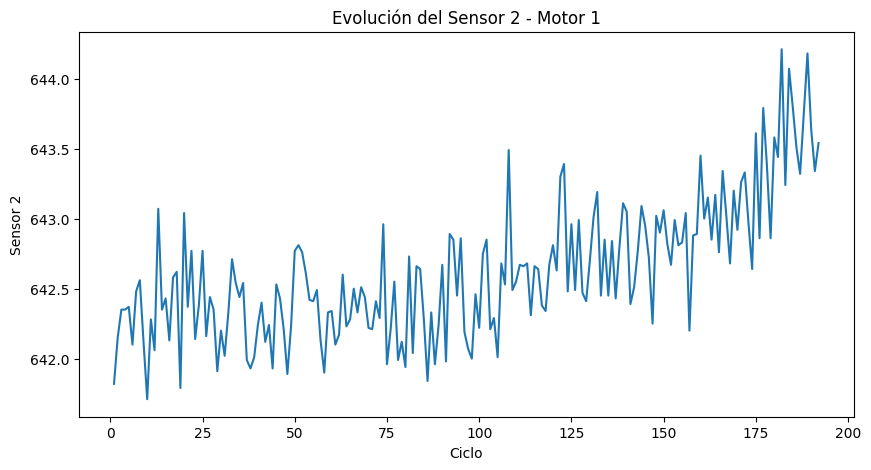

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(engine_1["cycle"], engine_1["sensor_2"])

plt.xlabel("Ciclo")
plt.ylabel("Sensor 2")
plt.title("Evolución del Sensor 2 - Motor 1")

plt.show()

La representación del `sensor_2` para el motor 1 muestra fluctuaciones entre ciclos, coherentes con la presencia de ruido en las mediciones indicada en la documentación del dataset.

A pesar de estas fluctuaciones, se aprecia visualmente una **tendencia creciente a medida que avanza la vida del motor**, especialmente durante los últimos ciclos. Los valores registrados al final de la serie son, en general, superiores a los observados durante las primeras etapas.

Este comportamiento sugiere que el sensor podría contener información relacionada con la evolución temporal y la degradación del motor. Sin embargo, el análisis de una única unidad no es suficiente para establecer esta relación, por lo que será necesario comprobar si el patrón se reproduce en otros motores y analizar el comportamiento del resto de sensores.

#### 2.1.2 Evolución temporal de los sensores del motor 1

A continuación, se representa la evolución de las 21 mediciones de sensores a lo largo de los 192 ciclos del motor 1.

El objetivo es identificar visualmente diferentes comportamientos en las señales, como tendencias crecientes o decrecientes, variables constantes, ruido o posibles cambios asociados al avance de la vida del motor.

En esta fase el análisis es únicamente exploratorio y no se pretende determinar todavía qué sensores son relevantes para el modelado.

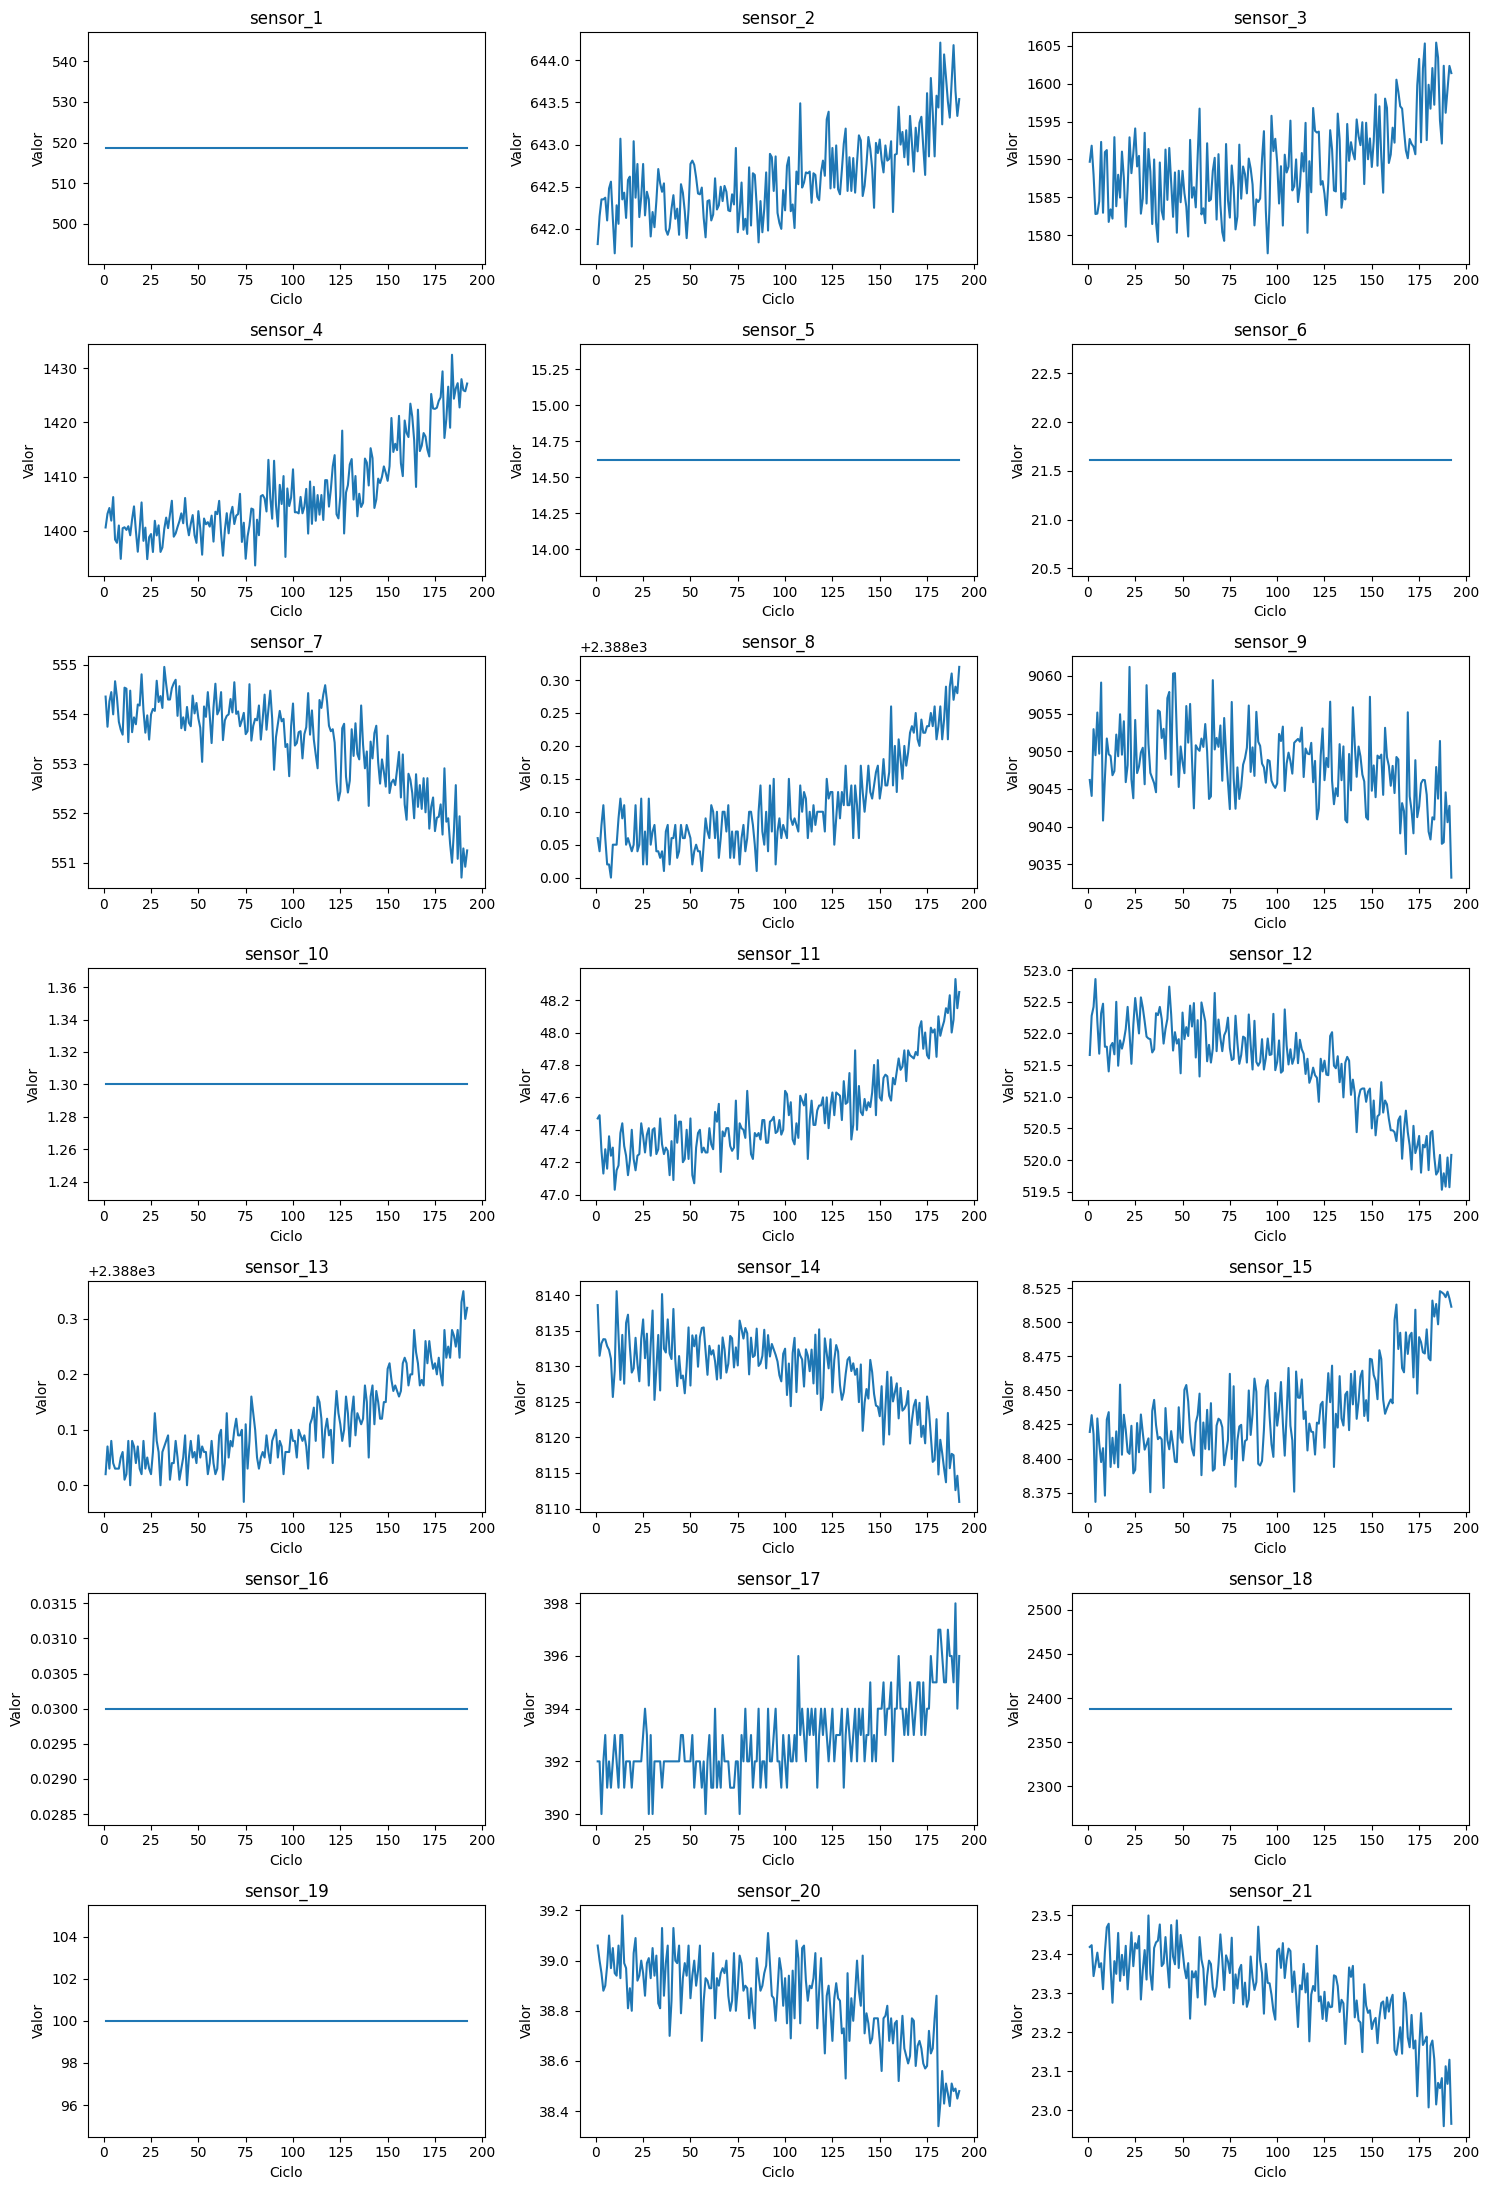

In [ ]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

fig, axes = plt.subplots(7, 3, figsize=(15, 22))
axes = axes.flatten()

for i, sensor in enumerate(sensor_cols):
    axes[i].plot(engine_1["cycle"], engine_1[sensor])
    axes[i].set_title(sensor)
    axes[i].set_xlabel("Ciclo")
    axes[i].set_ylabel("Valor")

plt.tight_layout()
plt.show()

La representación conjunta de los 21 sensores permite observar diferentes comportamientos a lo largo de los 192 ciclos del motor 1.

En primer lugar, se confirma visualmente que los sensores `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` permanecen constantes durante toda la serie. El `sensor_6` también presenta una variabilidad muy reducida, que visualmente no se aprecia, pero sabemos de antes que tiene 2 valores distintos durante los ciclos.

Entre los sensores restantes se observan diferentes tendencias temporales. Los sensores 2, 3, 4, 8, 11, 13, 15 y 17 presentan visualmente una tendencia general creciente, mientras que los sensores 7, 9, 12, 14, 20 y 21 muestran una tendencia decreciente.

En varios casos, las señales permanecen relativamente estables durante los primeros ciclos y las tendencias se hacen más evidentes conforme el motor se aproxima al final de su vida útil. Estas tendencias aparecen acompañadas de fluctuaciones asociadas al ruido presente en las mediciones.

Este análisis corresponde únicamente al motor 1 y, por tanto, no permite concluir todavía que estos patrones sean generales. Será necesario comprobar si comportamientos similares aparecen en otros motores antes de relacionarlos de forma consistente con el proceso de degradación.

### 2.2 Comparación entre diferentes motores

El análisis del motor 1 ha permitido identificar visualmente diferentes patrones temporales en las señales de los sensores. Sin embargo, para determinar si estos comportamientos están relacionados de forma general con el proceso de degradación, es necesario comprobar si se reproducen en otros motores.

Dado que las unidades presentan diferentes longitudes de vida, se seleccionarán motores con distintas duraciones para comparar la evolución de sus sensores.

In [ ]:
cycles_per_engine.sort_values()

,cycle
unit,
39,128
91,135
70,137
57,137
24,147
...,...
83,293
67,313
96,336


La ordenación muestra que las trayectorias presentan duraciones comprendidas entre 128 y 362 ciclos. A partir de esta distribución se seleccionarán motores con longitudes diferentes, de forma que la comparación incluya trayectorias cortas, intermedias y largas.

#### 2.2.1 Selección de motores representativos

Con el objetivo de comparar motores con diferentes longitudes de trayectoria, se seleccionan cinco unidades representativas de la distribución de duraciones: el motor con la trayectoria mínima, los motores más próximos al primer cuartil (Q1), la mediana y el tercer cuartil (Q3), y el motor con la trayectoria máxima.

In [ ]:
durations = cycles_per_engine

targets = {
    "Mínimo": durations.min(),
    "Q1": durations.quantile(0.25),
    "Mediana": durations.median(),
    "Q3": durations.quantile(0.75),
    "Máximo": durations.max()
}

for name, target in targets.items():
    unit = (durations - target).abs().idxmin()
    print(f"{name}: Motor {unit} - {durations[unit]} ciclos")

Mínimo: Motor 39 - 128 ciclos
Q1: Motor 87 - 178 ciclos
Mediana: Motor 26 - 199 ciclos
Q3: Motor 75 - 229 ciclos
Máximo: Motor 69 - 362 ciclos


Para comprobar si los patrones observados en el motor 1 se reproducen en otras unidades, se han seleccionado cinco motores representativos de diferentes longitudes de vida.

La selección incluye los motores correspondientes a las duraciones mínima y máxima y los motores cuyas duraciones se encuentran más próximas al primer cuartil (Q1), la mediana y el tercer cuartil (Q3).

| Posición | Motor | Número de ciclos |
|---|---:|---:|
| Mínimo | 39 | 128 |
| Primer cuartil (Q1) | 87 | 178 |
| Mediana | 26 | 199 |
| Tercer cuartil (Q3) | 75 | 229 |
| Máximo | 69 | 362 |

Esta selección permite analizar motores con vidas útiles considerablemente diferentes y comprobar si los patrones temporales observados en los sensores son consistentes entre unidades.

A partir de esta selección, se plantea la siguiente cuestión:

**¿Las tendencias que vimos en los sensores del motor 1 también aparecen en motores con vidas diferentes?**

#### 2.2.2 Cálculo de la vida útil restante (RUL)

Para comparar la evolución de motores con diferentes longitudes de vida es conveniente expresar su estado en función de los **ciclos restantes hasta el final de su vida útil**, mediante la variable **RUL (Remaining Useful Life)**.

En el conjunto de entrenamiento, cada motor dispone de observaciones hasta el final de su trayectoria. Por tanto, la RUL puede calcularse directamente como la diferencia entre el último ciclo registrado para cada motor y el ciclo actual:

**RUL = ciclo máximo del motor - ciclo actual**

De esta forma, una RUL igual a 0 corresponde al último ciclo de la serie, mientras que valores mayores indican el número de ciclos que todavía quedan hasta dicho punto.

Esta variable permitirá alinear motores con distintas duraciones respecto a su final de vida y facilitar la comparación de la evolución de sus sensores.

In [ ]:
df["RUL"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]

In [ ]:
# Comprobación de que ha sido creada correctamente
df[df["unit"] == 1][["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [ ]:
df[df["unit"] == 1][["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


La comparación de las primeras y últimas observaciones del motor 1 permite verificar que la variable RUL se ha calculado correctamente.

El motor 1 dispone de 192 ciclos. En el primer ciclo presenta una **RUL de 191 ciclos**, que disminuye progresivamente a medida que avanza su vida útil. En los últimos ciclos, la RUL toma los valores 4, 3, 2, 1 y finalmente **0 en el ciclo 192**, correspondiente al final de la serie del motor.

Por tanto, la variable RUL representa en cada observación el número de ciclos restantes hasta el final de la vida útil registrada del motor.

#### 2.2.3 Motores seleccionados

A partir de la selección realizada anteriormente, se genera un subconjunto de datos que contiene únicamente las observaciones correspondientes a los cinco motores representativos. Este subconjunto se utilizará para comparar la evolución temporal de sus sensores.

In [ ]:
selected_engines = [39, 87, 26, 75, 69]
df_selected = df[df["unit"].isin(selected_engines)]

#### 2.2.4 Comparación del sensor 2 entre motores mediante RUL

Una vez calculada la RUL, es posible comparar motores con diferentes longitudes de vida tomando como referencia su distancia al final de la serie.

Se seleccionan los cinco motores representativos obtenidos anteriormente y se analiza inicialmente el comportamiento del `sensor_2`.

A diferencia de la representación basada en el número de ciclo, utilizar la RUL permite alinear las distintas series respecto a su final de vida. De esta forma, **RUL = 0 representa el último ciclo de todos los motores**, independientemente de la duración total de cada uno.

Para facilitar la interpretación temporal, el eje de RUL se representa de forma decreciente, de manera que la gráfica se lea desde una RUL elevada al inicio de la vida hacia RUL = 0 al final.

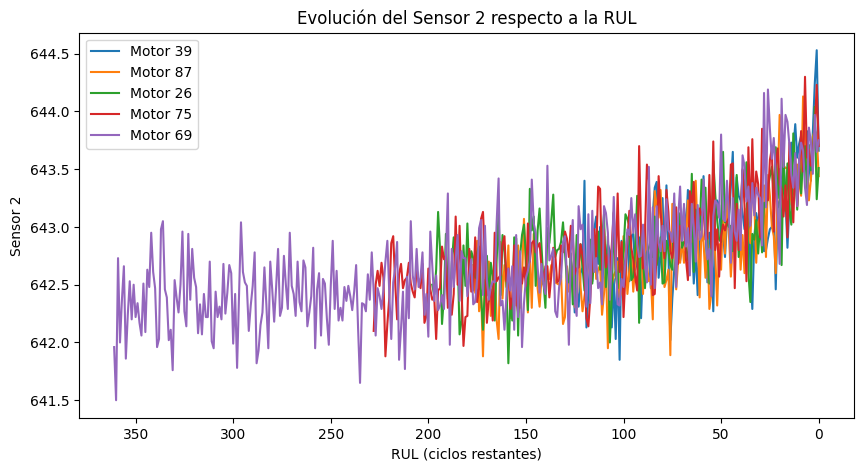

In [ ]:
plt.figure(figsize=(10, 5))

for unit in selected_engines:
    engine = df_selected[df_selected["unit"] == unit]
    plt.plot(engine["RUL"], engine["sensor_2"], label=f"Motor {unit}")

plt.xlabel("RUL (ciclos restantes)")
plt.ylabel("Sensor 2")
plt.title("Evolución del Sensor 2 respecto a la RUL")

plt.gca().invert_xaxis()

plt.legend()
plt.show()

La representación del `sensor_2` respecto a la RUL permite comparar directamente motores con diferentes longitudes de vida, alineando todas las series respecto a su último ciclo (`RUL = 0`).

A pesar del ruido presente en las mediciones y de las diferencias individuales entre motores, se observa un comportamiento similar en las cinco unidades seleccionadas. El valor del `sensor_2` presenta una **tendencia general creciente conforme disminuye la RUL**, haciéndose especialmente evidente en las etapas próximas al final de la vida útil.

Este resultado indica que el patrón observado inicialmente en el motor 1 también aparece en motores con diferentes duraciones, lo que sugiere que el `sensor_2` podría contener información relacionada con el proceso de degradación y la proximidad al final de la vida útil.

No obstante, esta observación es únicamente exploratoria y no permite determinar todavía la capacidad predictiva del sensor.

#### 2.2.5 Comparación de los 21 sensores entre diferentes motores

Tras comprobar que la tendencia observada en el `sensor_2` se reproduce en los cinco motores seleccionados, se amplía el análisis a las 21 señales disponibles.

El objetivo es comprobar si los comportamientos identificados inicialmente en el motor 1 (sensores constantes y señales con tendencias crecientes o decrecientes) se mantienen en motores con diferentes longitudes de vida.

Las series se representan respecto a la RUL, de forma que todos los motores quedan alineados en su último ciclo (`RUL = 0`). Esto permite comparar el comportamiento de los sensores en función de la proximidad al final de la vida útil y no del número absoluto de ciclos recorridos.

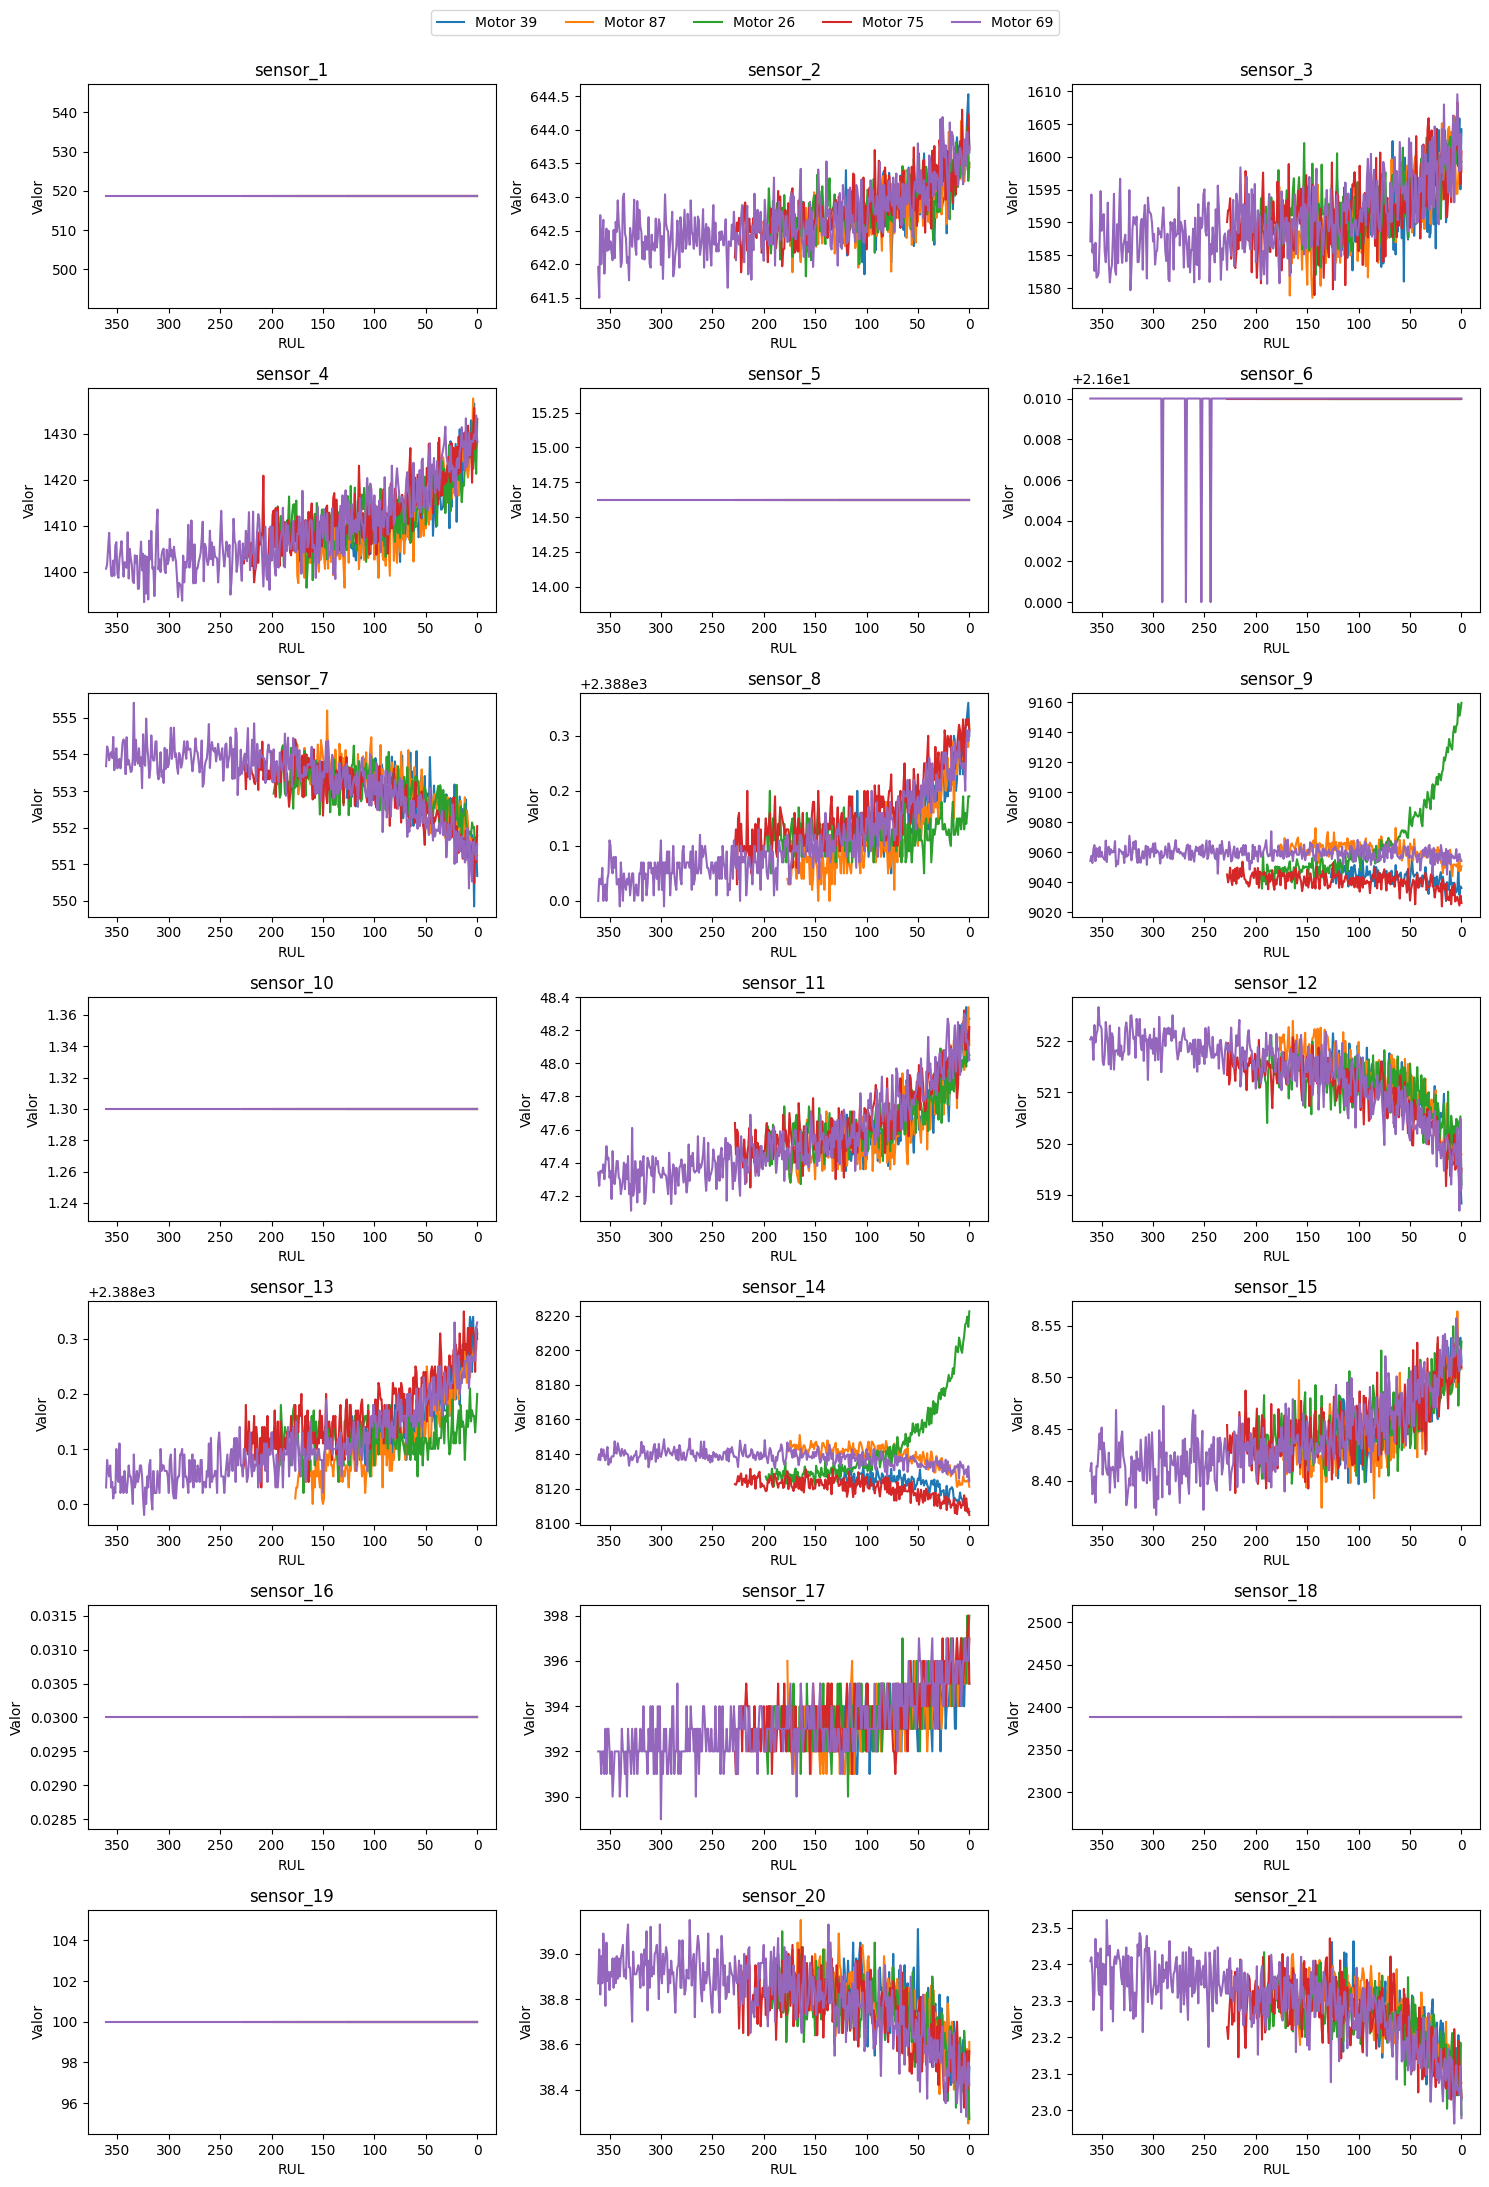

In [ ]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

fig, axes = plt.subplots(7, 3, figsize=(15, 22))
axes = axes.flatten()

for i, sensor in enumerate(sensor_cols):

    for unit in selected_engines:
        engine = df_selected[df_selected["unit"] == unit]

        axes[i].plot(
            engine["RUL"],
            engine[sensor],
            label=f"Motor {unit}"
        )

    axes[i].set_title(sensor)
    axes[i].set_xlabel("RUL")
    axes[i].set_ylabel("Valor")
    axes[i].invert_xaxis()

# Leyenda común para todos los sensores
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=True
)

# Reservar espacio superior para la leyenda
plt.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()

La comparación de las 21 señales en cinco motores con diferentes longitudes de vida permite comprobar que varios de los patrones identificados inicialmente en el motor 1 se reproducen entre distintas unidades.

Los sensores `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` permanecen constantes, mientras que `sensor_6` presenta una variabilidad muy reducida.

Entre los sensores variables se observan tendencias relativamente consistentes respecto a la disminución de la RUL. Los sensores 2, 3, 4, 8, 11, 13, 15 y 17 presentan, en general, tendencias crecientes al aproximarse al final de la vida útil. Por el contrario, los sensores 7, 12, 20 y 21 muestran tendencias generalmente decrecientes.

Los sensores 9 y 14 presentan un comportamiento menos consistente entre las unidades seleccionadas, observándose diferencias importantes entre las trayectorias de algunos motores.

Este análisis muestra que la degradación del sistema parece reflejarse mediante la evolución conjunta de múltiples sensores y no mediante una única señal. No obstante, estas conclusiones son todavía exploratorias, ya que se basan en una selección de cinco motores. Posteriormente será necesario analizar cuantitativamente el comportamiento del conjunto completo de unidades antes de realizar una selección de variables.

### 2.3 Relación entre los sensores y la RUL

Tras identificar visualmente diferentes patrones de evolución en una selección de motores, se amplía el análisis al conjunto completo de las 100 unidades de FD001.

Como primera aproximación cuantitativa, se analiza la correlación entre las mediciones de los sensores y la vida útil restante (RUL). Este análisis permite estudiar si existe una relación lineal entre el valor de cada sensor y la proximidad al final de la vida útil.

Una correlación positiva indica que el valor del sensor tiende a aumentar cuando la RUL es mayor, mientras que una correlación negativa indica que el sensor tiende a aumentar a medida que la RUL disminuye.

Los valores próximos a cero indican una relación lineal débil o inexistente. No obstante, una correlación baja no implica necesariamente que el sensor carezca de información útil, ya que podrían existir relaciones no lineales o patrones temporales más complejos.

In [ ]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]
correlations = df[sensor_cols + ["RUL"]].corr()["RUL"].drop("RUL")
correlations.sort_values()

,RUL
sensor_11,-0.696228
sensor_4,-0.678948
sensor_15,-0.642667
sensor_2,-0.606484
sensor_17,-0.606154
sensor_3,-0.584520
sensor_8,-0.563968
sensor_13,-0.562569
sensor_9,-0.390102
sensor_14,-0.306769


El análisis de correlación confirma cuantitativamente varios de los patrones identificados durante la exploración visual.

Los sensores 11, 4, 15, 2, 17, 3, 8 y 13 presentan correlaciones negativas moderadas o elevadas con la RUL. Esto indica que sus valores tienden a aumentar conforme disminuye la vida útil restante del motor.

Por otro lado, los sensores 12, 7, 21 y 20 presentan correlaciones positivas relativamente elevadas, indicando que sus valores tienden a disminuir conforme el motor se aproxima al final de su vida útil.

Los sensores 9 y 14 presentan relaciones lineales más débiles con la RUL, lo que coincide con el comportamiento menos consistente observado entre los diferentes motores durante el análisis gráfico. El sensor 6 presenta una correlación especialmente reducida y una variabilidad muy limitada.

Finalmente, los sensores 1, 5, 10, 16, 18 y 19 presentan valores `NaN`. Esto no se debe a la existencia de datos ausentes, sino a que son variables constantes y, por tanto, no es posible calcular su correlación.

En conjunto, los resultados muestran que varios sensores presentan una relación clara con la proximidad al final de la vida útil. Sin embargo, la correlación mide únicamente relaciones lineales y no considera completamente la estructura temporal de las señales, por lo que no se utilizará de forma aislada para determinar la relevancia definitiva de las variables.

Las correlaciones se calculan sobre el conjunto de observaciones de los 100 motores, por lo que constituyen una medida descriptiva global. Dado que las observaciones de cada motor están relacionadas temporalmente y que las trayectorias presentan diferentes longitudes, estos coeficientes no deben interpretarse como evidencia de una relación idéntica en todos los motores ni como una medida definitiva de capacidad predictiva.

Por tanto, este análisis se utiliza para comprender el comportamiento de los sensores respecto a la RUL, mientras que la selección de variables para el modelado se justificará posteriormente, teniendo en cuenta la independencia de los conjuntos de entrenamiento y validación.

#### 2.3.1 Visualización de la correlación entre los sensores y la RUL

Para facilitar la interpretación de las correlaciones obtenidas, se representan gráficamente los coeficientes de correlación entre cada sensor y la RUL.

La representación permite identificar de forma visual tanto la **dirección de la relación** (positiva o negativa) como su **intensidad**. Los sensores constantes, cuya correlación no puede calcularse, se excluyen de esta visualización.

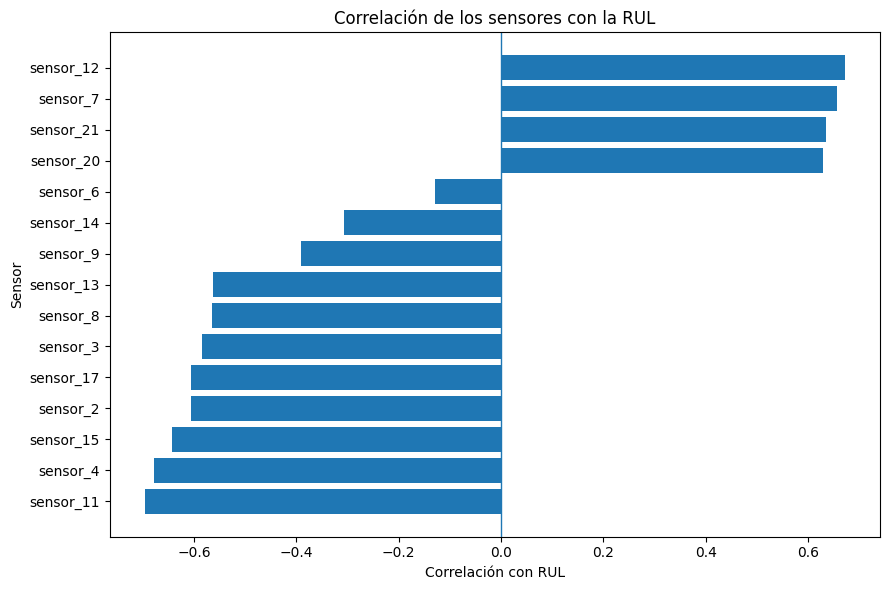

In [ ]:
# Eliminar los sensores constantes (NaN) y ordenar las correlaciones
corr_plot = correlations.dropna().sort_values()

plt.figure(figsize=(9, 6))

plt.barh(corr_plot.index, corr_plot.values)

plt.axvline(0, linewidth=1)

plt.xlabel("Correlación con RUL")
plt.ylabel("Sensor")
plt.title("Correlación de los sensores con la RUL")

plt.tight_layout()
plt.show()

La representación permite observar dos grupos principales de sensores relacionados con la evolución de la RUL.

Por un lado, los sensores 11, 4, 15, 2, 17, 3, 8 y 13 presentan las correlaciones negativas de mayor magnitud. Esto indica que sus valores tienden a aumentar conforme disminuye la vida útil restante.

Por otro lado, los sensores 12, 7, 21 y 20 presentan correlaciones positivas elevadas, por lo que sus valores tienden a disminuir conforme el motor se aproxima al final de su vida útil.

Los sensores 9 y 14 muestran una relación lineal menos intensa, mientras que el sensor 6 presenta una correlación especialmente reducida.

Los sensores constantes no aparecen en la representación debido a que su correlación con la RUL no puede calcularse.

Estos resultados refuerzan los patrones identificados previamente mediante el análisis visual. No obstante, la magnitud de la correlación no debe interpretarse directamente como una medida definitiva de importancia predictiva, ya que pueden existir relaciones no lineales y dependencias temporales que este coeficiente no captura.

## 3. Conclusiones del análisis inicial

En este notebook se ha realizado una primera exploración del subconjunto de entrenamiento **FD001** del dataset C-MAPSS con el objetivo de comprender su estructura y el comportamiento temporal de las variables antes de abordar las etapas de preprocesamiento y modelado.

El conjunto de datos contiene **20.631 observaciones correspondientes a 100 motores**, cada uno representado mediante una serie temporal completa hasta el final de su vida simulada. Las trayectorias presentan diferentes longitudes, comprendidas entre **128 y 362 ciclos**, con una duración media de **206,31 ciclos**.

El análisis de las variables ha mostrado que el conjunto de datos no contiene valores ausentes y que todas las variables son numéricas. También se han identificado seis sensores constantes (`sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19`) y un sensor con una variabilidad muy reducida (`sensor_6`). Además, las variables presentan escalas numéricas diferentes, aspecto que deberá considerarse posteriormente durante el preprocesamiento.

El estudio de las series temporales ha permitido observar que varios sensores presentan tendencias a medida que los motores se aproximan al final de su trayectoria. Estas tendencias se han analizado inicialmente en el motor 1 y posteriormente en cinco motores con diferentes longitudes de vida, utilizando la **RUL (Remaining Useful Life)** como referencia común para alinear sus trayectorias respecto al final de vida.

Finalmente, el análisis de correlación realizado sobre el conjunto completo de FD001 ha mostrado que varios sensores presentan una relación lineal apreciable con la RUL. Entre ellos, algunos aumentan conforme disminuye la vida útil restante, mientras que otros presentan el comportamiento contrario. No obstante, estas relaciones son todavía exploratorias y no deben interpretarse como una selección definitiva de variables, ya que la correlación lineal no captura posibles relaciones no lineales ni toda la estructura temporal de las señales.

En conjunto, este análisis proporciona una primera caracterización de FD001 y permite identificar patrones potencialmente relacionados con la evolución de los motores. Estos resultados servirán como base para las siguientes etapas del trabajo, en las que se profundizará en el análisis de los distintos subconjuntos de C-MAPSS y posteriormente se abordarán el preprocesamiento y el modelado.